# Laborator 4, Rețele Markov

5 variabile binare $A_1,\dots,A_5$, conexiuni $A_1\!-\!A_2$, $A_1\!-\!A_3$, $A_2\!-\!A_4$, $A_2\!-\!A_5$, $A_3\!-\!A_4$, $A_4\!-\!A_5$.

Potențial pe clica maximală $C$: $\ \phi_C(a_C)=e^{\,\beta\sum_{i<j\in C} a_i a_j}$.

In [1]:
import itertools, math
import pyagrum as gum

nodes = ["A1", "A2", "A3", "A4", "A5"]
edges = [("A1","A2"), ("A1","A3"), ("A2","A4"), ("A2","A5"), ("A3","A4"), ("A4","A5")]

mrf = gum.MarkovRandomField()
for v in nodes:
    mrf.add(gum.IntegerVariable(v, v, [0, 1]))

# Fiecare muchie = un factor (deocamdată constant) ca să existe în graf.
for a, b in edges:
    f = gum.Tensor()
    f.add(mrf.variable(a))
    f.add(mrf.variable(b))
    f.fillWith(1)
    mrf.addFactor(f)

## a) Graf și clici

Vizualizăm rețeaua Markov în pyAgrum (necesită Graphviz).

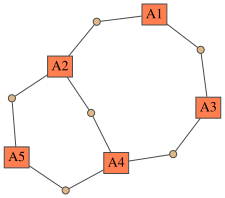

In [2]:
import pyagrum.lib.notebook as gnb
gnb.showMRF(mrf)

Clicile maximale le citim direct din graf. Singura clică de dimensiune 3 este triunghiul $\{A_2,A_4,A_5\}$ (muchiile $A_2\!-\!A_4$, $A_4\!-\!A_5$, $A_2\!-\!A_5$ există toate). Celelalte muchii nu închid niciun triunghi, deci rămân clici de dimensiune 2:

$$\{A_1,A_2\},\quad \{A_1,A_3\},\quad \{A_3,A_4\},\quad \{A_2,A_4,A_5\}.$$

In [3]:
cliques = [["A1", "A2"], ["A1", "A3"], ["A3", "A4"], ["A2", "A4", "A5"]]

## b) Probabilitate comună și stări de probabilitate maximă

$P(a)=\frac1Z\prod_C\phi_C(a_C)$, cu $Z=\sum_a\prod_C\phi_C(a_C)$. Evaluăm pe cele $2^5$ stări.

In [4]:
beta = 0.5

def weight(state):
    a = dict(zip(nodes, state))
    energy = sum(a[i] * a[j] for c in cliques for i, j in itertools.combinations(c, 2))
    return math.exp(beta * energy)

weights = {s: weight(s) for s in itertools.product([0, 1], repeat=5)}
Z = sum(weights.values())
P = {s: w / Z for s, w in weights.items()}  # probabilitatea comuna

for s, p in P.items():
    print(s, round(p, 4))

best = max(P, key=P.get)
print("\nmaxim:", best, round(P[best], 4))

(0, 0, 0, 0, 0) 0.0103
(0, 0, 0, 0, 1) 0.0103
(0, 0, 0, 1, 0) 0.0103
(0, 0, 0, 1, 1) 0.017
(0, 0, 1, 0, 0) 0.0103
(0, 0, 1, 0, 1) 0.0103
(0, 0, 1, 1, 0) 0.017
(0, 0, 1, 1, 1) 0.0281
(0, 1, 0, 0, 0) 0.0103
(0, 1, 0, 0, 1) 0.017
(0, 1, 0, 1, 0) 0.017
(0, 1, 0, 1, 1) 0.0463
(0, 1, 1, 0, 0) 0.0103
(0, 1, 1, 0, 1) 0.017
(0, 1, 1, 1, 0) 0.0281
(0, 1, 1, 1, 1) 0.0763
(1, 0, 0, 0, 0) 0.0103
(1, 0, 0, 0, 1) 0.0103
(1, 0, 0, 1, 0) 0.0103
(1, 0, 0, 1, 1) 0.017
(1, 0, 1, 0, 0) 0.017
(1, 0, 1, 0, 1) 0.017
(1, 0, 1, 1, 0) 0.0281
(1, 0, 1, 1, 1) 0.0463
(1, 1, 0, 0, 0) 0.017
(1, 1, 0, 0, 1) 0.0281
(1, 1, 0, 1, 0) 0.0281
(1, 1, 0, 1, 1) 0.0763
(1, 1, 1, 0, 0) 0.0281
(1, 1, 1, 0, 1) 0.0463
(1, 1, 1, 1, 0) 0.0763
(1, 1, 1, 1, 1) 0.2074

maxim: (1, 1, 1, 1, 1) 0.2074


Starea de probabilitate maximă este $(1,1,1,1,1)$: cu $\beta>0$ fiecare pereche de vecini pe 1 crește potențialul.

## c) Modelul Ising

$e^{\beta a_i a_j}$ favorizează doar perechea $(1,1)$. Pentru a favoriza vecinii cu aceeași valoare (și $(0,0)$), folosim un indicator de egalitate: $\ \phi_C(a_C)=e^{\,\beta\sum_{i<j}\mathbb{1}[a_i=a_j]}$.`

In [5]:
def ising_weight(state):
    a = dict(zip(nodes, state))
    energy = sum(a[i] == a[j] for c in cliques for i, j in itertools.combinations(c, 2))
    return math.exp(beta * energy)

weights = {s: ising_weight(s) for s in itertools.product([0, 1], repeat=5)}
Z = sum(weights.values())
m = max(weights.values())

print("P maxima =", round(m / Z, 4))
print([s for s, w in weights.items() if w == m])

P maxima = 0.1141
[(0, 0, 0, 0, 0), (1, 1, 1, 1, 1)]


Acum ambele stări omogene, $(0,0,0,0,0)$ și $(1,1,1,1,1)$, sunt maxime.